In [1]:
!python -u benchmark_nuevo.py        # el -u muestra el progreso en vivo

BENCHMARK  |  time.perf_counter()  |  CSV incremental

Cargando 'numeros.txt'
Se cargaron 500,000 números en memoria.

REANUDANDO: 'resultados.csv' ya contiene 38 combinaciones medidas; esas se omitirán.
(Para medir todo de nuevo: borrar resultados.csv o ponerREANUDAR = False.)

[mezcla] n = 500: ya estaba en el CSV, se omite.
[mezcla] n = 1,000: ya estaba en el CSV, se omite.
[mezcla] n = 10,000: ya estaba en el CSV, se omite.
[mezcla] n = 30,000: ya estaba en el CSV, se omite.
[mezcla] n = 50,000: ya estaba en el CSV, se omite.
[mezcla] n = 100,000: ya estaba en el CSV, se omite.
[mezcla] n = 200,000: ya estaba en el CSV, se omite.
[mezcla] n = 300,000: ya estaba en el CSV, se omite.
[mezcla] n = 400,000: ya estaba en el CSV, se omite.
[mezcla] n = 500,000: ya estaba en el CSV, se omite.
[quicksort] n = 500: ya estaba en el CSV, se omite.
[quicksort] n = 1,000: ya estaba en el CSV, se omite.
[quicksort] n = 10,000: ya estaba en el CSV, se omite.
[quicksort] n = 30,000: ya estaba en e

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# utf-8-sig bytes ocultos al inicio del archivo que dejó
# el benchmark). Sin esto, la columna se llamaría '\ufefftamaño_muestra'.
df = pd.read_csv("resultados.csv", encoding="utf-8-sig")

# gráficas
ORDEN = ["insercion", "burbuja", "seleccion", "mezcla", "quicksort"]

ETIQUETAS = {
    "insercion": "Inserción  O(n²)",
    "burbuja":   "Burbuja  O(n²)",
    "seleccion": "Selección  O(n²)",
    "mezcla":    "Mezcla (merge)  O(n·log n)",
    "quicksort": "Quicksort  O(n·log n)",
}
COLORES = {   # O(n²) cálidos, O(n log n) fríos
    "insercion": "#d62728", "burbuja": "#ff7f0e", "seleccion": "#8c564b",
    "mezcla":    "#1f77b4", "quicksort": "#2ca02c",
}
MARCADORES = {"insercion": "o", "burbuja": "s", "seleccion": "^",
              "mezcla": "D", "quicksort": "v"}

def leyendasGeneral(ax):
    """Reetiqueta la leyenda de seaborn con acentos y complejidad."""
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [ETIQUETAS.get(l, l) for l in labels],
              title="Algoritmo", loc="upper left")

# Orden fijo de algoritmos y puntos ordenados por tamaño (líneas correctas)
df["algoritmo"] = pd.Categorical(df["algoritmo"], categories=ORDEN, ordered=True)
df = df.sort_values(["algoritmo", "tamaño_muestra"]).reset_index(drop=True)

print(f"Filas cargadas: {len(df)}   (esperadas: 38)")
print(df.to_string())

Filas cargadas: 38   (esperadas: 38)
    tamaño_muestra  algoritmo  tiempo_promedio
0              500  insercion         0.009000
1             1000  insercion         0.031912
2             5000  insercion         0.633105
3            10000  insercion         2.636721
4            20000  insercion        11.018668
5            30000  insercion        25.418920
6              500    burbuja         0.011199
7             1000    burbuja         0.045900
8             5000    burbuja         1.296445
9            10000    burbuja         5.082828
10           20000    burbuja        20.936984
11           30000    burbuja        49.182165
12             500  seleccion         0.005274
13            1000  seleccion         0.021677
14            5000  seleccion         0.540843
15           10000  seleccion         2.286190
16           20000  seleccion         9.335707
17           30000  seleccion        21.441462
18             500     mezcla         0.000762
19            1000     

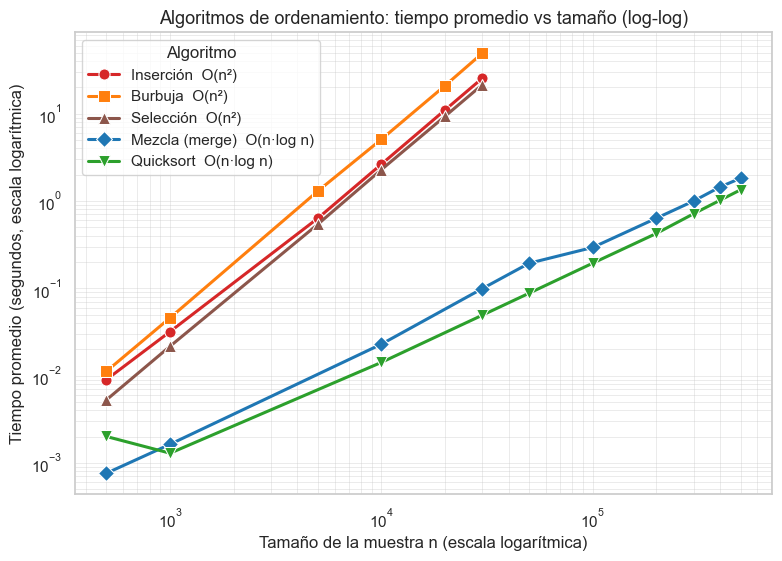

Guardada: grafica1_loglog.png


In [3]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=df, x="tamaño_muestra", y="tiempo_promedio",
    hue="algoritmo", hue_order=ORDEN,
    style="algoritmo", markers=MARCADORES, dashes=False,
    palette=COLORES, linewidth=2.2, markersize=8, ax=ax,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(True, which="both", linewidth=0.4, alpha=0.7)  # rejilla también en menores

ax.set_title("Algoritmos de ordenamiento: tiempo promedio vs tamaño (log-log)",
             fontsize=13)
ax.set_xlabel("Tamaño de la muestra n (escala logarítmica)")
ax.set_ylabel("Tiempo promedio (segundos, escala logarítmica)")
leyendasGeneral(ax)

fig.savefig("grafica1_loglog.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardada: grafica1_loglog.png")

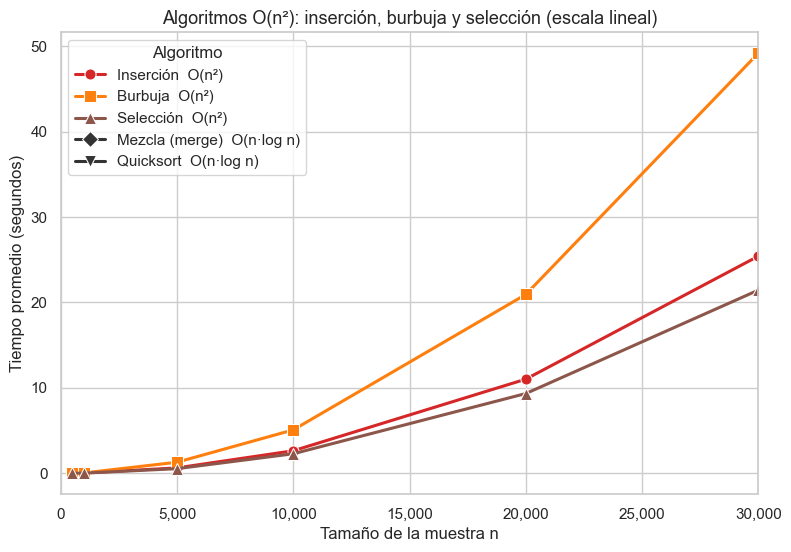

Guardada: grafica2_on2.png


In [4]:
LENTOS = ["insercion", "burbuja", "seleccion"]
df_lentos = df[df["algoritmo"].isin(LENTOS)]

fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=df_lentos, x="tamaño_muestra", y="tiempo_promedio",
    hue="algoritmo", hue_order=LENTOS,
    style="algoritmo", markers=MARCADORES, dashes=False,
    palette=COLORES, linewidth=2.2, markersize=8, ax=ax,
)

ax.set_xlim(0, 30_000)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

ax.set_title("Algoritmos O(n²): inserción, burbuja y selección (escala lineal)",
             fontsize=13)
ax.set_xlabel("Tamaño de la muestra n")
ax.set_ylabel("Tiempo promedio (segundos)")
leyendasGeneral(ax)

fig.savefig("grafica2_on2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardada: grafica2_on2.png")

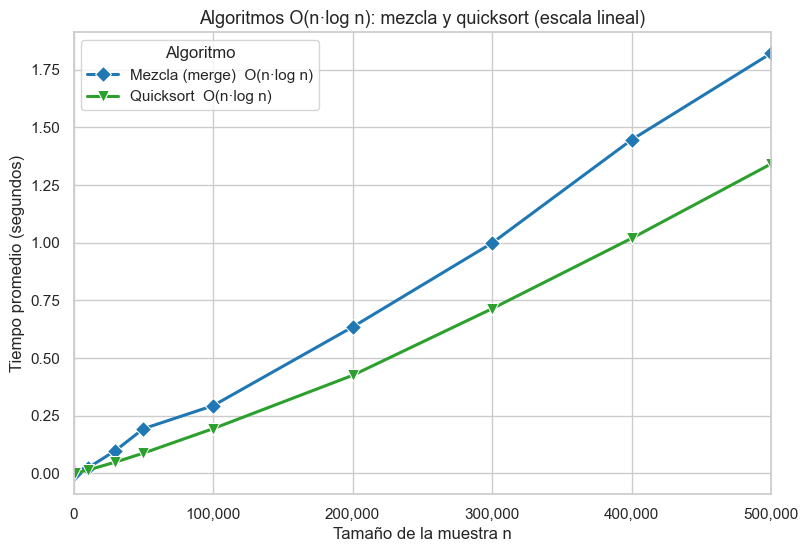

Guardada: grafica3_nlogn.png


In [7]:
RAPIDOS = ["mezcla", "quicksort"]
df_rapidos = df[df["algoritmo"].isin(RAPIDOS)]

fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=df_rapidos, x="tamaño_muestra", y="tiempo_promedio",
    hue="algoritmo", hue_order=RAPIDOS,
    style="algoritmo", markers=MARCADORES, dashes=False,
    palette=COLORES, linewidth=2.2, markersize=8, ax=ax,
)

ax.set_xlim(0, 500_000)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

ax.set_title("Algoritmos O(n·log n): mezcla y quicksort (escala lineal)",
             fontsize=13)
ax.set_xlabel("Tamaño de la muestra n")
ax.set_ylabel("Tiempo promedio (segundos)")
leyendasGeneral(ax)

fig.savefig("grafica3_nlogn.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardada: grafica3_nlogn.png")

In [ ]:
import pandas as pd
import numpy as np

# Cargar los datos
df = pd.read_csv("resultados.csv")

print("AJUSTE DE CURVAS (Regresión Log-Log)\n")
print(f"{'Algoritmo':<12} | {'Exponente (p)':<15} | {'Función ajustada':<25} | {'Complejidad Teórica'}")
print("-" * 85)

for alg in df['algoritmo'].unique():
    datos = df[df['algoritmo'] == alg]
    x = datos['tamaño_muestra'].values
    y = datos['tiempo_promedio'].values

    #ceros o negativos en el logaritmo
    mask = (x > 0) & (y > 0)
    x, y = x[mask], y[mask]

    # Ajuste lineal en escala logarítmica: log(y) = p * log(x) + log(k)
    # La pendiente 'p' es el exponente de la función de crecimiento
    log_x = np.log(x)
    log_y = np.log(y)
    pendiente, intercepto = np.polyfit(log_x, log_y, 1)

    # Determinar la función teórica basada en la pendiente
    if pendiente > 1.8:
        funcion_ajustada = f"O(n^{pendiente:.2f}) ≈ O(n²)"
        teoria = "O(n²)"
    elif pendiente > 1.0 and pendiente < 1.5:
        funcion_ajustada = f"O(n^{pendiente:.2f}) ≈ O(n log n)"
        teoria = "O(n log n)"
    else:
        funcion_ajustada = f"O(n^{pendiente:.2f})"
        teoria = "Lineal / Otra"

    print(f"{alg:<12} | {pendiente:<15.3f} | {funcion_ajustada:<25} | {teoria}")

print("\nLa pendiente (exponente) confirma la complejidad teórica de cada algoritmo.")

AJUSTE DE CURVAS (Regresión Log-Log)

Algoritmo    | Exponente (p)   | Función ajustada          | Complejidad Teórica
-------------------------------------------------------------------------------------
mezcla       | 1.126           | O(n^1.13) ≈ O(n log n)    | O(n log n)
quicksort    | 1.015           | O(n^1.01) ≈ O(n log n)    | O(n log n)
insercion    | 1.938           | O(n^1.94) ≈ O(n²)         | O(n²)
burbuja      | 2.046           | O(n^2.05) ≈ O(n²)         | O(n²)
seleccion    | 2.028           | O(n^2.03) ≈ O(n²)         | O(n²)

La pendiente (exponente) confirma la complejidad teórica de cada algoritmo.
